<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200"/>
</p></center>

<center><font size=10>Artificial Intelligence and Machine Learning</center></font>
<center><font size=6>MLS 1 - Linear Regression</center></font>

<center><p float="center">
  <img src="https://images.pexels.com/photos/7163956/pexels-photo-7163956.jpeg" alt="health-insurance" width="640"/>
</p></center>

<center><font size=6>Health Insurance Premium Prediction</center></font>

# **Problem Statement**


## Business Context

BluePeak Health Plans is a mid-sized health insurance carrier headquartered in Nashville, TN, serving individual policyholders across the Southeast and Midwest.

BluePeak prices individual health policies using broad demographic bands (age group and region), a model that treats a 45-year-old non-smoker on the Bronze plan the same as a 45-year-old smoker on the Gold plan in the same region. As healthcare costs have continued to rise post-ACA, this blunt approach is creating an adverse selection problem: price-sensitive low-risk customers are leaving for leaner competitors, while high-risk individuals, who are underpriced relative to their actual claims, are staying and renewing. The result is a worsening loss ratio that the actuarial team can see in claims data (approximately 1 in 5 high-risk applicants is currently underpriced by more than $3,000 in annual expected charges) but cannot systematically address with the current pricing infrastructure.

The underwriting team manually flags high-risk applications for override, but there are no consistent rules, no documented criteria, and no way to apply the process at scale during open enrollment when application volumes spike. The VP of Underwriting needs a model that predicts expected annual medical charges per applicant at the point of policy issuance using variables already collected on every application (age, number of dependents, smoking status, region, and plan type), so that pricing reflects actual individual risk rather than demographic averages.

**Constraints:**

**Process**: The manual flagging workflow has no documented criteria. Different underwriters apply different thresholds, making decisions inconsistent and difficult to defend to state regulators.

**Platform:** The current policy issuance system has no individual-level scoring capability. The model output will be delivered through a simple web-based scoring interface where underwriters enter five application fields, receive a predicted annual charge, and see an actuarially defined risk tier at the point of decision.

**People:** The actuarial team has experience with band-based pricing but no prior exposure to dynamic pricing based on predictive mathematical models. Adoption will require interpretable outputs rather than black-box scores.


## Objective

Build a linear regression model that predicts individual annual medical charges using age, number of dependents, smoking status, region, and plan type, and identify which factors most strongly drive cost so that BluePeak can move from band-based pricing to individual risk-based pricing. The model should be accurate enough to meaningfully differentiate low-risk from high-risk applicants and simple enough for the underwriting team to translate into concrete pricing rules.

## Data Description

The dataset consists of the following key attributes:

- **age**: Age of the insured individual.
- **children**: Number of dependents.
- **smoker**: Smoking status (yes / no).
- **region**: Residential region (northeast, northwest, southeast, southwest).
- **plan**: Selected insurance plan (Bronze, Silver, Gold).
- **charges**: Insurance premium charged to the individual (target variable).

# **Installing and Importing Necessary Libraries**


In [1]:
!pip install pandas==2.2.2\
             numpy==2.0.2\
             matplotlib==3.10.0\
             seaborn==0.13.2\
             scikit-learn==1.6.1\
             statsmodels==0.14.6\
             scipy==1.16.3

  Using cached pandas-2.2.2.tar.gz (4.4 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached numpy-2.0.2.tar.gz (18.9 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... error
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [634 lines of output]
      + /Users/sahithid/Desktop/repos/.venv/bin/python3.13 /private/var/folders/tr/nxngyvq93lnc4gcmr34lfp9r0000gn/T/pip-install-21egxyh7/numpy_a62f155ffd96489a864185b69e0479dc/vendored-meson/meson/meson.py setup /private/var/folders/tr/nxngyvq93lnc4gcmr34lfp9r0000gn/T/pip-install-21egxyh7/numpy_a62f155ffd96489a864185b69e0479dc /private/var/folders/tr/nxngyvq93lnc4gcmr34lfp9r0000gn/T/pip-install-21egx

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

***Prompt***:

<font size=3 color="#4682B4">Generate a Python import cell for a Linear Regression case study, including data handling, visualization, preprocessing, model building, evaluation metrics, statsmodels for OLS, and warning suppression. Add concise comments and return only code.
</font>

In [2]:
# Import libraries for reading and manipulating data
import pandas as pd
# Import library for numerical operations
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import utilities for performance evaluation
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

# Import utilities for data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import statsmodels for OLS regression
import statsmodels.api as sm

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')


# **Loading the Data**


With our libraries in place, the next step is to load the dataset that will drive our analysis. In this case, we are working with an insurance dataset that contains information about individuals such as age, number of dependents, smoking status, region, and selected plan type.



***Prompt***:

<font size=3 color="#4682B4">Load the insurance_charges.csv file and store it as data.
</font>

In [5]:
data = pd.read_csv('/Users/sahithid/Desktop/repos/UTA-JULY2026/W3 - Week 1 Linear Regression/W3 MLS - Linear Regression/insurance_charges.csv')

- The CSV file can also be directly loaded from Google Drive.

***Prompt***:

<font size=3 color="#4682B4">Load the insurance_prediction_aca.csv file from Google Drive and store it as data.
</font>

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

# # Load the dataset
# data = pd.read_csv('/content/drive/insurance_prediction_aca.csv')

# **Data Overview**

Now that the dataset is loaded, it's important to understand its structure and content before diving into deeper analysis. This step involves:

- Checking the number of rows and columns.
- Viewing the first and last few rows.
- Examining data types and missing values.
- Generating basic descriptive statistics.

***Prompt***:

<font size=3 color="#4682B4">Display the number of rows and columns in the data.
</font>

In [6]:
data.shape

(1338, 6)

The dataset consists of **1,338 rows** and **6 columns**.

***Prompt***:

<font size=3 color="#4682B4">Display the first 10 rows of the data.
</font>

In [7]:
data.head(10)

,age,children,smoker,region,plan,charges
0,19,0,yes,southwest,Silver,11788.66
1,18,1,no,southeast,Bronze,6483.12
2,28,3,no,southeast,Silver,6156.17
3,33,0,no,northwest,Gold,6550.05
4,32,0,no,northwest,Bronze,10362.04
5,31,0,no,southeast,Bronze,10692.06
6,46,1,no,southeast,Silver,9835.06
7,37,3,no,northwest,Gold,10676.99
8,37,2,no,northeast,Silver,13155.18
9,60,0,no,northwest,Gold,10634.50


***Prompt***:

<font size=3 color="#4682B4">Display the last 10 rows of the data.
</font>

In [8]:
data.tail(10)

,age,children,smoker,region,plan,charges
1328,23,2,no,northeast,Gold,5525.57
1329,52,2,no,southwest,Silver,7088.88
1330,57,2,no,southeast,Silver,12602.64
1331,23,0,no,southwest,Silver,4487.27
1332,52,3,no,southwest,Gold,15956.46
1333,50,3,no,northwest,Gold,12516.62
1334,18,0,no,northeast,Bronze,1744.03
1335,18,0,no,southeast,Bronze,2810.37
1336,21,0,no,southwest,Bronze,500.00
1337,61,0,yes,northwest,Bronze,12594.92


***Prompt***:

<font size=3 color="#4682B4">Display the column names, data types, and number of rows in the data.
</font>



The code provides a summary of the DataFrame, including the number of non-null entries, data types, and memory usage.

In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   children  1338 non-null   int64  
 2   smoker    1338 non-null   str    
 3   region    1338 non-null   str    
 4   plan      1338 non-null   str    
 5   charges   1338 non-null   float64
dtypes: float64(1), int64(2), str(3)
memory usage: 62.8 KB


- The dataset contains **6 columns** and **1,338 rows**, with **no missing values**.
- Data types are as expected:
  - **Numeric:** `age`, `children`, `charges`
  - **Categorical:** `smoker`, `region`, `plan`


***Prompt***:

<font size=3 color="#4682B4">Display the statistical summary of the numerical data.
</font>

In [10]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0,27.000,39.000,51.000,64.00
children,1338.0,1.094918,1.205493,0.0,0.000,1.000,2.000,5.00
charges,1338.0,9852.747511,3588.235727,500.0,7298.795,9933.295,12479.195,20453.48


**Observations:**
1. **Age:** Average age is around **39 years**, ranging from **18 to 64**.
2. **Children:** Most individuals have **0-2 dependents**, with a maximum of 5.
3. **Charges:** Premium charges range from roughly **\$500 to \$20,500**, with a mean of about **\$9,850**.

***Prompt***:

<font size=3 color="#4682B4">Display the summary of categorical variables.
</font>

In [11]:
data.describe(include='object')

,smoker,region,plan
count,1338,1338,1338
unique,2,4,3
top,no,southeast,Bronze
freq,1064,364,509


**Observations:**
- **Smoking Status:** Non-smokers dominate the sample (≈80% non-smokers, ≈20% smokers).
- **Region:** Fairly even distribution across the four regions.


***Prompt***:

<font size=3 color="#4682B4">How many duplicate rows are present in the data?
</font>

In [12]:
# Identify duplicate rows
duplicate_rows = data[data.duplicated()]

# Print the number of duplicate rows
print(f"Number of duplicate rows: {len(duplicate_rows)}")

Number of duplicate rows: 0


***Prompt***:

<font size=3 color="#4682B4">Drop the duplicate rows if any.
</font>

In [13]:
# Drop duplicate rows
data = data.drop_duplicates()

# Print the shape of the DataFrame after removing duplicates
print(f"Shape after removing duplicates: {data.shape}")

Shape after removing duplicates: (1338, 6)


# **Exploratory Data Analysis**

With a basic understanding of our dataset, it's time to dive deeper through Exploratory Data Analysis (EDA). This step is crucial for uncovering hidden patterns and relationships between features.



**Note:** The EDA section has been covered extensively in the previous case studies. In this case study, we will mainly focus on the model building aspects and will only look at the key observations from EDA. The detailed EDA can be found in the [*Appendix: Extended EDA*](#Appendix) section.

## Univariate Analysis


***Prompt***:

<font size=3 color="#4682B4">Visualize the distribution of the target variable (charges) in the data.
</font>

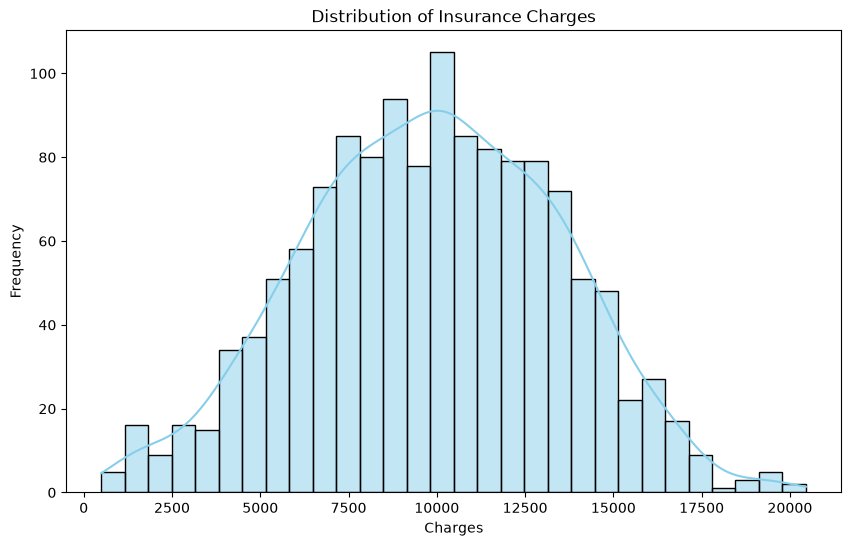

In [18]:
# Distribution of insurance charges (target variable)
plt.figure(figsize=(10, 6))
sns.histplot(data['charges'], kde=True, bins=30, color='skyblue')
plt.title('Distribution of Insurance Charges')
plt.xlabel('Charges')
plt.ylabel('Frequency')
plt.show()


**Observation:**
* Annual charges span roughly 500 to 20,500, with a mean of about 9,850 and a median close to 9,930, so the centre of the distribution sits around the 10,000 mark.
* The distribution is broadly symmetric with a mild right tail, driven by a small group of high-cost policyholders. This is exactly the behaviour a risk-based pricing model needs to capture.

***Prompt***:

<font size=3 color="#4682B4">Visualize the distribution of age in the data.
</font>

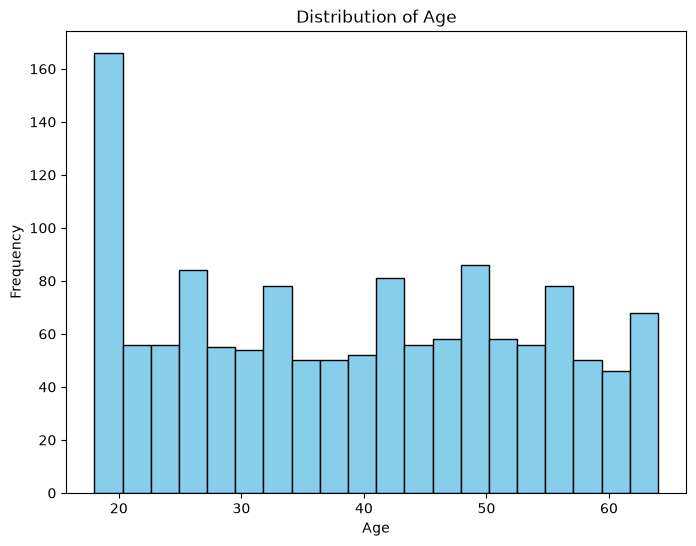

In [15]:
# Histogram of age
plt.figure(figsize=(8, 6))
plt.hist(data['age'], bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

**Observation:**
* Age ranges from 18 to 64, with a heavier concentration in the lower age brackets (roughly 18 to 25).
* Younger individuals are well represented in the book of business, which will help the model learn the age effect at the lower end of the age band.

***Prompt***:

<font size=3 color="#4682B4">Visualize the distribution of smoker status in the data.
</font>

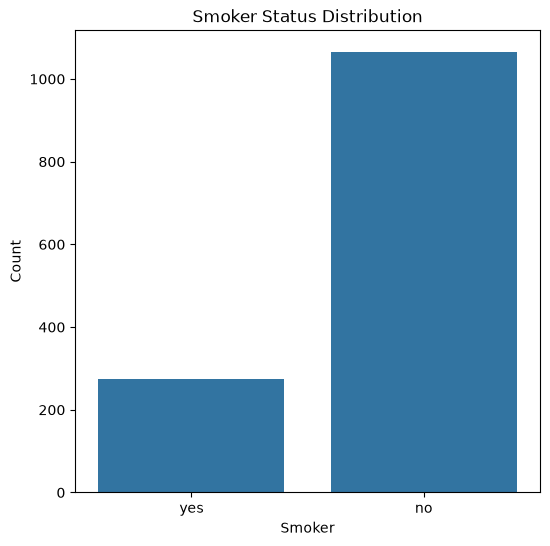

In [16]:
# Distribution of smoker status
plt.figure(figsize=(6, 6))
sns.countplot(x='smoker', data=data)
plt.title('Smoker Status Distribution')
plt.xlabel('Smoker')
plt.ylabel('Count')
plt.show()

**Observation:**
* Non-smokers make up roughly 80 percent of the sample and smokers roughly 20 percent, an approximate 4 to 1 ratio.
* The class imbalance is worth noting, but smoker status is expected to be one of the most informative predictors of medical charges.

## Bivariate Analysis

***Prompt***:

<font size=3 color="#4682B4">Visualize how insurance charges vary with age.
</font>

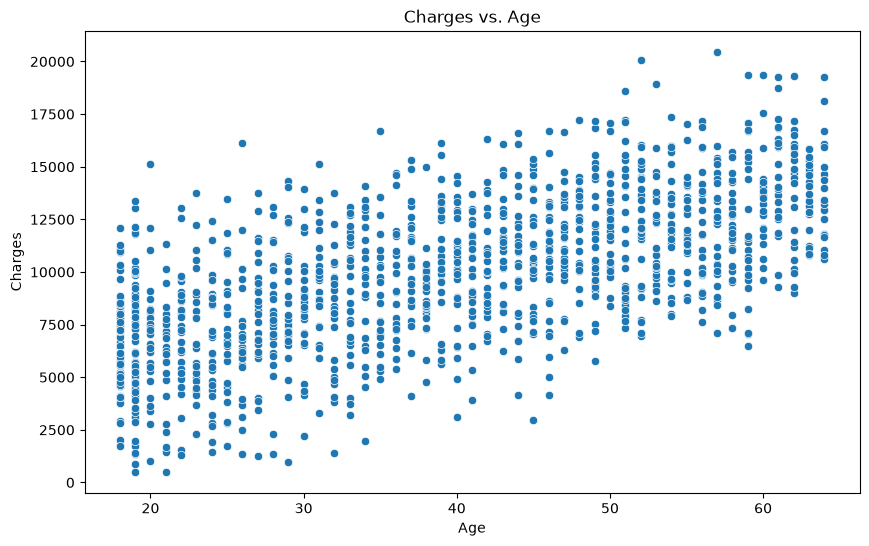

In [19]:
# Scatter plot of charges vs age
plt.figure(figsize=(10, 6))
sns.scatterplot(x='age', y='charges', data=data)
plt.title('Charges vs. Age')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.show()

**Observations:**
* Charges generally rise with age, confirming the positive relationship suggested by the correlation of about 0.65.
* The scatter shows distinct horizontal bands, which is a hint that other factors such as smoker status and plan type are layered on top of the age effect. We will confirm this in the multivariate model.

***Prompt***:

<font size=3 color="#4682B4">Visualize how insurance charges vary with smoker status.
</font>

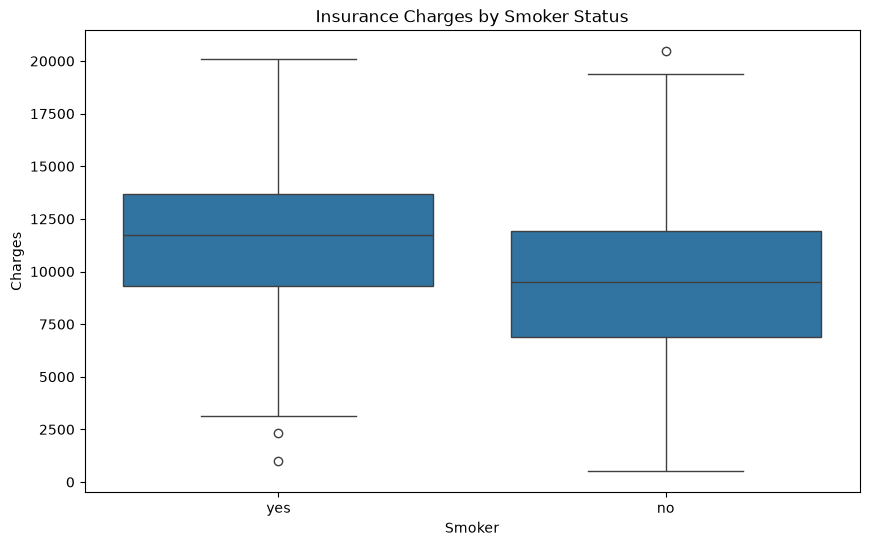

In [20]:
# Compare charges for smokers vs. non-smokers
plt.figure(figsize=(10, 6))
sns.boxplot(x='smoker', y='charges', data=data)
plt.title('Insurance Charges by Smoker Status')
plt.xlabel('Smoker')
plt.ylabel('Charges')
plt.show()

**Observations:**
* Smokers are charged noticeably more than non-smokers on average, with median charges roughly 11,750 for smokers compared with about 9,500 for non-smokers.
* Smoker status is one of the strongest categorical drivers of the premium and needs to be carried into the model.

***Prompt***:

<font size=3 color="#4682B4">Visualize how insurance charges vary with plan type.
</font>

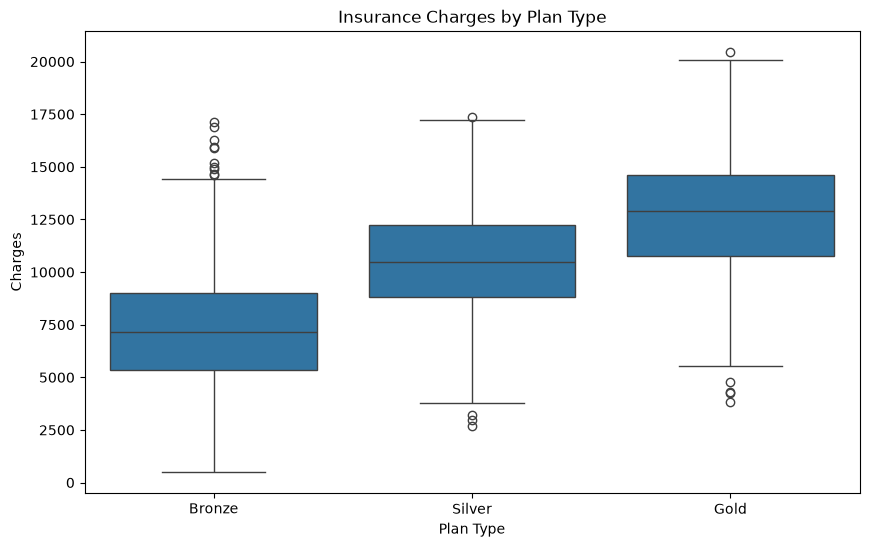

In [21]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='plan', y='charges', data=data, order=['Bronze', 'Silver', 'Gold'])
plt.title('Insurance Charges by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Charges')
plt.show()

**Observations:**
* Charges rise monotonically as we move from Bronze to Silver to Gold, with median charges of roughly 7,150 for Bronze, 10,500 for Silver, and 12,900 for Gold.
* Plan tier is a clean, monotonic driver of the premium and pairs well with individual risk features to explain overall charges.

## Correlation Heatmap


***Prompt***:

<font size=3 color="#4682B4">Visualize the numerical columns using a correlation heatmap.
</font>

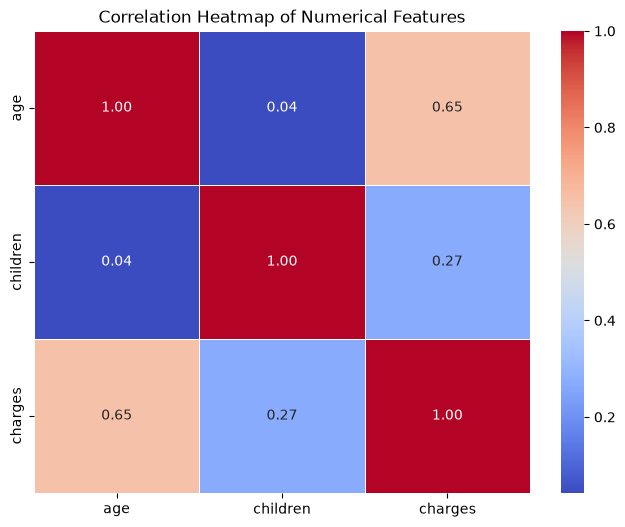

In [22]:
# Correlation matrix for numerical features
numerical_cols = ['age', 'children', 'charges']
correlation_matrix = data[numerical_cols].corr()

# Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

**Observations:**
* Age has the strongest positive correlation with charges at about 0.65, making it the dominant numerical driver.
* Children is only weakly correlated with charges at about 0.27, so it will help the model but will not carry it on its own.
* Age and children themselves are only weakly correlated with each other, so the two numerical predictors carry independent information.

# **Data Preprocessing**

To begin, we aim to build three linear regression models:

1. In the first model, we use only the **age** column to build a **Simple Linear Regression** model.
2. In the second model, we use only the **numerical features** (`age`, `children`) to build a **Multiple Linear Regression** model.
3. In the third model, we use **all features** including the encoded categorical ones.

Before that, we need to encode the categorical variables.


## Data Encoding

***Prompt***:

<font size=3 color="#4682B4">Dummy encode the categorical columns ('smoker', 'region', 'plan') in the data using dtype=int.
</font>



In [23]:
data = pd.get_dummies(
    data,
    columns=['smoker', 'region', 'plan'],
    drop_first=True,
    dtype=int
)

**NOTE :** We use **`dtype=int`** in dummy encoding to guarantee that the output is numerical (`0` and `1`), as it may otherwise default to Boolean values (`True` and `False`).

***Prompt***:

<font size=3 color="#4682B4">Show the first 10 rows of the data.
</font>

In [ ]:
data.head(10)

## Train-Test Split

Now that the categorical variables are encoded, it's time to split our entire dataset into two parts for training and testing.

***Prompt***:

<font size=3 color="#4682B4">Split the data into training and testing sets, using `charges` as the dependent variable (`y`). Use 85% of the data for training and 15% for testing.
</font>

In [ ]:
# Split data into features (X) and target (y)
X = data.drop('charges', axis=1)
y = data['charges']

# Split into training and testing sets (85/15)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

***Prompt***:

<font size=3 color="#4682B4">Check the shape of the training and testing data.
</font>

In [ ]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

The training and testing datasets are properly split, with **85%** of the data used for training and **15%** for testing.

# **Model Building**

## Model Evaluation Criterion

In insurance price prediction, the model can make two types of mistakes:

* **Underestimating the price**, when the predicted premium is lower than it should be.
* **Overestimating the price**, when the predicted premium is higher than it should be.

We use the following metrics to evaluate model performance:
- **MAPE (Mean Absolute Percentage Error):** Average percentage deviation of predictions from actuals; lower is better.
- **RMSE (Root Mean Squared Error):** Square root of MSE; in the same unit as the target.
- **R² (R-squared):** Proportion of variance in the target explained by the model; closer to 1 is better.
- **Adjusted R²:** A version of R-squared that adjusts for the number of predictors in the model.
    - Unlike R-squared, it only increases when a new feature genuinely improves the model beyond what would be expected by chance, and can decrease if a feature adds no real value.
    - This makes it a more reliable metric when comparing models with different numbers of predictors.

## Utility Functions

Define utility functions to simplify OLS model training and prediction throughout the analysis.

***Prompt***:

<font size=3 color="#4682B4">Create a reusable function to fit an OLS regression model, automatically adding an intercept term before training.
</font>

In [ ]:
# Add these two functions:
def ols_fit(X, y):
    return sm.OLS(y, sm.add_constant(X)).fit()

***Prompt***:

<font size=3 color="#4682B4">Create a reusable function to generate predictions from a trained OLS model, ensuring the intercept term is added to the input data before prediction.
</font>

In [ ]:
def ols_predict(model, X):
    return model.predict(sm.add_constant(X, has_constant='add'))


Now, we create a blank DataFrame to store the training and testing metrics of the different models.

***Prompt***:

<font size=3 color="#4682B4">Generate Python code to create an empty DataFrame named model_eval_results with columns for model name and training/testing metrics (MAPE, RMSE, and R²).
</font>

In [ ]:
model_eval_results = pd.DataFrame(
    columns=['Model', 'Train_Mape', 'Train_RMSE', 'Train_R2','Train_Adj_R2',
             'Test_Mape', 'Test_RMSE', 'Test_R2','Test_Adj_R2']
)

Next, we define a reusable function to evaluate any model and store its results.

***Prompt***:

<font size=3 color="#4682B4">Define a function that takes a model name, a trained regression model, and the training and testing datasets as inputs. The function should calculate MAPE, RMSE, and R² for both datasets, append the results to `model_eval_results`, and display the metrics in a readable format.
</font>

In [ ]:
def adj_r2_score(predictors, target, pred):
    """Compute adjusted R-squared."""
    r2 = r2_score(target, pred)
    n = predictors.shape[0]              # number of observations
    k = predictors.shape[1]              # number of predictors (excluding intercept)
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


def evaluate_model(model_name, model, X_train, X_test, y_train, y_test):
    """Evaluates the model on train and test data and appends results to model_eval_results."""
    global model_eval_results

    # Predict on training and testing data
    y_train_pred = ols_predict(model, X_train)
    y_test_pred  = ols_predict(model, X_test)

    # Training metrics
    train_mse    = mean_squared_error(y_train, y_train_pred)
    train_rmse   = np.sqrt(train_mse)
    train_r2     = r2_score(y_train, y_train_pred)
    train_adjr2  = adj_r2_score(X_train, y_train, y_train_pred)   # adjusted R-squared

    # Testing metrics
    test_mse    = mean_squared_error(y_test, y_test_pred)
    test_rmse   = np.sqrt(test_mse)
    test_r2     = r2_score(y_test, y_test_pred)
    test_adjr2  = adj_r2_score(X_test, y_test, y_test_pred)       # adjusted R-squared

    train_mape = mean_absolute_percentage_error(y_train, y_train_pred)
    test_mape  = mean_absolute_percentage_error(y_test, y_test_pred)

    # Append to results
    model_eval_results.loc[len(model_eval_results)] = [
        model_name,
        round(train_mape, 2), round(train_rmse, 2), round(train_r2, 4), round(train_adjr2, 4),
        round(test_mape,  2), round(test_rmse,  2), round(test_r2,  4), round(test_adjr2,  4)
    ]

    # Print formatted output
    print(f"\u2500\u2500\u2500 {model_name} \u2500\u2500\u2500")
    print(f"  Train  \u2192  Mape: {train_mape:.4f}   RMSE: {train_rmse:>10,.2f}   R\u00b2: {train_r2:.4f}   Adj R\u00b2: {train_adjr2:.4f}")
    print(f"  Test   \u2192  Mape: {test_mape:.4f}   RMSE: {test_rmse:>10,.2f}   R\u00b2: {test_r2:.4f}   Adj R\u00b2: {test_adjr2:.4f}")

    return

## Model Building


With the data preprocessed and ready, we begin our modelling phase using Ordinary Least Squares (OLS) Regression from `statsmodels`. OLS estimates the linear relationship between the independent variables and the target variable and returns readable coefficients we can connect to business language.

We will progressively build three models with different feature sets and compare their predictive performance.

### Model 1



In the first model, we use only the `age` feature to demonstrate how simple linear regression works and how it performs.

***Prompt***:

<font size=3 color="#4682B4"> Train an OLS regression model using `age` as the predictor and `charges` as the target variable. Fit the model on the training data and store the trained model for further evaluation.

</font>

In [ ]:
# Define features (X) and target (y) for Model 1 (Age only)
X_train_m1 = X_train[['age']]
X_test_m1  = X_test[['age']]

# Initialize and train the model
model_1 = ols_fit(X_train_m1, y_train)

***Prompt***:

<font size=3 color="#4682B4">Display the OLS model summary for Model 1.
</font>

**NOTE:**
- The OLS summary below outputs multiple diagnostic statistics. For this case study, we focus on R-squared, Adjusted R-squared, the intercept (`const`), and the feature coefficients.
- We discussed R-squared and Adjusted R-squared previously.
- The intercept (`const`) represents the baseline expected charge when all input variables equal zero.
- The coefficients indicate the direction and magnitude of change in the predicted charge for a one-unit change in a feature, holding all other variables constant.

In [ ]:
print(model_1.summary())

**Observation:**
* **R-squared = 0.415 and Adjusted R-squared = 0.415**, meaning age alone explains about 41.5 percent of the variation in annual charges.
    - The remaining 58.5 percent is driven by factors this model does not see, such as smoker status and plan tier.
* **const (intercept) = 3,483.24**, which is the predicted annual charge for a hypothetical policyholder of age 0.
    - It is a mathematical anchor and not a business quantity.
* **age coefficient = 163.40**, meaning a one unit increase in age will result in an increase of ~163 units in the predicted annual charge.
* While age is a meaningful predictor on its own, but the moderate R-squared confirms that a single-feature model is not enough to price policies accurately.

**NOTE**:
- The above interpretation of a linear regression coefficient holds true ONLY when the assumptions of linear regression are satisfied.
- We'll be discussing these assumptions in a subsequent session.


Now, let's evaluate the model's performance.

***Prompt***:

<font size=3 color="#4682B4">Evaluate the model 1 performance on both the training and testing data using the `evaluate_model` function.
</font>

In [ ]:
evaluate_model('Model 1 (Age Only)', model_1, X_train_m1, X_test_m1, y_train, y_test)

**Observation:**
* Train R-squared of about 0.42 and Test R-squared of about 0.44 are close to each other, so the model is not overfitting.
* Train RMSE is about 2,728 and Test RMSE is about 2,749, both large relative to the mean charge of about 9,850.
* Train and Test MAPE both sit around 0.34, meaning the model is off by roughly 34 percent of the actual charge on a typical prediction.
* The model is clearly underfitting because it is working with only one feature.

### Model 2

In the second model, we use the numerical features (`age`, `children`) to train a multiple linear regression model.

***Prompt***:

<font size=3 color="#4682B4"> Train an OLS regression model using `age` and `children` as predictors and `charges` as the target variable. Fit the model on the training data and store the trained model for further evaluation.

</font>

In [ ]:
# Define features (X) and target (y) for Model 2 (numerical features)
num_features = ['age', 'children']
X_train_m2 = X_train[num_features]
X_test_m2  = X_test[num_features]

# Initialize and train the model
model_2 = ols_fit(X_train_m2, y_train)

***Prompt***:

<font size=3 color="#4682B4">Display the OLS model summary for Model 2.
</font>

In [ ]:
print(model_2.summary())

**Observation:**
* **R-squared = 0.483 and Adjusted R-squared = 0.482**. Adding `children` lifts the explained variance from 41.5 percent to 48.3 percent, a small but real improvement over Model 1.
* **Adjusted R-squared comparison:** Model 1 used only `age` and had an Adjusted R-squared of about 0.415. Model 2 adds one more predictor (`children`) and the Adjusted R-squared rises to about 0.482. Since Adjusted R-squared penalises adding predictors that do not carry real signal, this rise tells us `children` is a genuinely useful predictor and not just noise.
* **const (intercept) = 2,796.43**, again a mathematical baseline rather than a business quantity.
* **age coefficient = 159.55**, meaning each additional year of age is associated with an increase of roughly 160 in the predicted annual charge, holding `children` constant.
* **children coefficient = 765.42**, meaning each additional dependent is associated with an increase of about 765 in the predicted annual charge, holding age constant.
* The lift is modest because the model still ignores the strongest categorical drivers, smoker status and plan type.

***Prompt***:

<font size=3 color="#4682B4">Evaluate the model 2 performance on both the training and testing data.
</font>

In [ ]:
evaluate_model('Model 2 (Numerical Features)', model_2, X_train_m2, X_test_m2, y_train, y_test)

**Observation:**
* Train RMSE has dropped to about 2,565 and Test RMSE to about 2,724, a small improvement over Model 1.
* R-squared has risen from about 0.42 to 0.48 on train, but the test-set gain is modest, moving from about 0.44 to 0.45.
* MAPE has come down slightly from about 0.34 to 0.32 on train and from 0.34 to 0.33 on test, so the typical percentage error has only shifted a little.
* The model is still underfitting. To meaningfully close the gap we need to add the categorical features (`smoker`, `region`, `plan`).

### Model 3

Now, we use the entire dataset, including all numerical and encoded categorical features to build our final multiple linear regression model.



***Prompt***:

<font size=3 color="#4682B4"> Train an OLS regression model using all available features as predictors and `charges` as the target variable. Fit the model on the training data and store the trained model for further evaluation.

</font>

In [ ]:
# Initialize and train the Linear Regression model on all features
model_3 = ols_fit(X_train, y_train)

***Prompt***:

<font size=3 color="#4682B4">Display the OLS model summary for Model 3.
</font>

In [ ]:
print(model_3.summary())

**Observation:**
* **R-squared = 0.604 and Adjusted R-squared = 0.601**. The model explains about 60 percent of the variation in annual charges, a large jump over Model 2. The gap between R-squared and Adjusted R-squared is small, so the extra features are pulling their weight.
* **Adjusted R-squared trajectory across models:** Model 1 (only `age`) had an Adjusted R-squared of about 0.415. Model 2 (`age` and `children`) raised it to about 0.482. Model 3 now brings it up to about 0.601 by adding the categorical features `smoker`, `region`, and `plan`. The steady rise at every step confirms that each new set of predictors is contributing real explanatory power rather than simply inflating the fit.
* **const (intercept) = 3,358.50**, the mathematical baseline once all other features are set to zero (a non-smoker in the reference region on the reference plan).
* **Coefficient interpretation (each holding everything else constant):**
    * **age = 132.41**: each additional year of age adds about 132 to the predicted charge. The effect is smaller than in Model 1 because part of what age was picking up is now correctly attributed to plan and smoker.
    * **children = 514.14**: each additional dependent adds about 514 to the predicted charge.
    * **smoker_yes = 2,134.36**: smokers pay on average about 2,134 more than non-smokers of the same profile. Smoker status is the single largest categorical driver.
    * **plan_Gold = 2,331.09** and **plan_Silver = 989.93**: Gold policyholders pay about 2,331 more, and Silver policyholders about 990 more, than Bronze policyholders on the same profile.
    * **region_northwest = -605.98**, **region_southeast = -516.93**, **region_southwest = -1,337.68**: relative to the northeast (reference region), all three other regions have lower predicted charges, with the southwest being the cheapest.
* All coefficients are statistically significant, so every feature is contributing meaningful information to the prediction.

***Prompt***:

<font size=3 color="#4682B4">Evaluate the model 3 performance on both the training and testing data.
</font>

In [ ]:
evaluate_model('Model 3 (All Features)', model_3, X_train, X_test, y_train, y_test)

**Observation:**
* Train R-squared of about 0.60 and Test R-squared of about 0.65 are close, which tells us the model generalises well and is not overfitting.
* Test RMSE has dropped to about 2,171, an improvement of roughly 550 over Model 2.
* Test MAPE has fallen to about 0.26, so the typical prediction is off by around 26 percent of the actual charge, meaningfully better than the earlier two models.
* Adding the categorical features, particularly `smoker` and `plan`, is what closed most of the gap. This is now our best candidate model.

## Model Comparison

***Prompt***:

<font size=3 color="#4682B4">Show the model evaluation metrics in `model_eval_results`.
</font>

In [ ]:
model_eval_results

**Observations:**
* **RMSE trajectory:** Test RMSE falls from about 2,749 in Model 1, to 2,724 in Model 2, to 2,171 in Model 3. The biggest single jump comes from adding the categorical features in Model 3, which trims the typical prediction error by roughly 550 dollars per policy.
* **R-squared trajectory:** Test R-squared rises from about 0.44 in Model 1 to 0.45 in Model 2 and then to 0.65 in Model 3. Model 3 explains roughly 65 percent of the variation in charges on unseen data, which is a strong result for a pricing model built on only a handful of predictors.
* **Adjusted R-squared trajectory:** Train Adjusted R-squared moves from about 0.415 in Model 1 (only `age`), to 0.482 in Model 2 (after adding `children`), to 0.601 in Model 3 (after adding `smoker`, `region`, and `plan`). The steady rise at every step shows that each new set of predictors is genuinely improving the fit rather than simply padding it.
* **MAPE trajectory:** Test MAPE improves from about 0.34 in Model 1, to 0.33 in Model 2, to 0.26 in Model 3, matching the pattern seen in RMSE and R-squared.
* **Overfitting check:** Train and Test R-squared values are close for Model 3 (0.60 versus 0.65), so the model is generalising well rather than memorising the training set.
* **Verdict:** Model 3 is the strongest performer across all four metrics and is the model we take forward for pricing prediction.

# **Actionable Insights and Recommendation**

## Business Insights

1. **Smoker status is the single largest individual risk driver.** After controlling for age, dependents, region, and plan, smokers pay roughly **2,134 more per year** than otherwise identical non-smokers. In the raw data, mean charges for smokers are about **11,533** versus **9,420** for non-smokers.

2. **Age drives a steady, compounding cost effect.** Every additional year of age adds about **132 to the annual charge** in Model 3, and age is the strongest numerical predictor of charges (correlation of about **0.65** with charges).

3. **Plan tier translates cleanly into cost.** Median charges rise from about **7,150 (Bronze)** to **10,500 (Silver)** to **12,900 (Gold)**. In the model, Gold policyholders pay about **2,331 more** and Silver policyholders about **990 more** than Bronze holders of the same profile.

4. **Region matters less than lifestyle and plan.** The gap between the highest region (northeast, mean about **10,594**) and the lowest (southwest, mean about **9,104**) is only about 1,500, and in the model the southwest sits about **1,338 below** the northeast. Region is a useful adjustment but not a primary driver.

## Business Recommendations

1. **Adopt Model 3 as the production pricing model.** It delivers a Test R-squared of about **0.65** and a Test RMSE of about **2,171** on a mean charge near 9,850, which is accurate enough to move BluePeak from band-based pricing to individual risk-based pricing.

2. **Introduce a distinct smoker loading factor.** Given the roughly **2,134** annual cost differential, price smokers on a separate loading table and validate smoker declarations at underwriting to avoid non-disclosure risk.

3. **Refresh age curves in the underwriting engine.** Replace flat age bands with a continuous adjustment of about **132 per year of age**, so premiums step up smoothly year on year rather than jumping at band boundaries.

4. **Price plans in line with their observed cost curve.** Keep Bronze as the reference and price Silver about **990** above Bronze and Gold about **2,331** above Bronze on a like-for-like risk profile. Combined with the smoker and age adjustments above, this helps reduce cross-subsidy between low-risk and high-risk policyholders and materially lowers premium leakage on the portfolio.

<a id="Appendix"></a>
# **Appendix: Extended EDA**


The plots in this appendix are supporting views that are useful for a deeper look at the data.

Because the working `data` DataFrame has already been encoded (categorical columns replaced with dummy variables), we reload a fresh, unencoded copy into `data_eda` purely for these appendix visualizations.

In [ ]:
# Reload a fresh, unencoded copy of the dataset for appendix EDA
data_eda = pd.read_csv('/content/insurance_charges.csv').drop_duplicates().reset_index(drop=True)
data_eda.head()

## Appendix: Univariate Analysis

***Prompt***:

<font size=3 color="#4682B4">Visualize the distribution of children in the data.
</font>

In [ ]:
# Distribution of number of children
plt.figure(figsize=(8, 6))
sns.countplot(x='children', data=data_eda)
plt.title('Distribution of Number of Children')
plt.xlabel('Number of Children')
plt.ylabel('Count')
plt.show()

**Observation:**
- Most policyholders have 0 to 2 dependents. Very few have 4 or 5, so the model has limited signal at the top of the range.

***Prompt***:

<font size=3 color="#4682B4">Visualize the distribution of region in the data.
</font>

In [ ]:
# Distribution of region
plt.figure(figsize=(8, 6))
sns.countplot(x='region', data=data_eda)
plt.title('Region Distribution')
plt.xlabel('Region')
plt.ylabel('Count')
plt.show()

**Observation:**
- The four regions are fairly evenly represented, with the southeast slightly larger. This means region estimates are supported by a comparable number of observations across regions.

***Prompt***:

<font size=3 color="#4682B4">Visualize the distribution of insurance charges using a box plot.
</font>

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='charges', data=data_eda)
plt.title('Box Plot of Insurance Charges')
plt.xlabel('Charges')
plt.show()

**Observation:**
- The box plot confirms the spread of charges and highlights a small number of high-cost policyholders sitting outside the upper whisker.

***Prompt***:

<font size=3 color="#4682B4">Visualize the distribution of plan type in the data.
</font>

In [ ]:
# Distribution of plan type
plt.figure(figsize=(8, 6))
sns.countplot(x='plan', data=data_eda, order=['Bronze', 'Silver', 'Gold'])
plt.title('Plan Type Distribution')
plt.xlabel('Plan Type')
plt.ylabel('Count')
plt.show()


**Observation:**
* Bronze is the most subscribed plan (about 509 policies), followed by Silver (about 496) and Gold (about 333).
* The Bronze-heavy mix is consistent with a price-sensitive customer base skewed towards the entry-level tier.

## Appendix: Bivariate Analysis

***Prompt***:

<font size=3 color="#4682B4">Visualize how insurance charges vary with the number of children.
</font>

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='children', y='charges', data=data_eda)
plt.title('Insurance Charges by Number of Children')
plt.xlabel('Number of Children')
plt.ylabel('Charges')
plt.show()

**Observation:**
- Median charges edge up as the number of dependents increases, but the effect is far weaker than `smoker` or `plan` and levels off at 3+ dependents.

***Prompt***:

<font size=3 color="#4682B4">Visualize how insurance charges vary with region.
</font>

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='region', y='charges', data=data_eda)
plt.title('Insurance Charges by Region')
plt.xlabel('Region')
plt.ylabel('Charges')
plt.show()


**Observation:**
* Median charges differ only modestly across regions, from about 9,100 in the southwest to about 10,780 in the northeast.
* Region is a useful adjustment for the model but is not a primary driver of charges.

## Appendix: Multivariate Analysis

***Prompt***:

<font size=3 color="#4682B4">Visualize the interaction between age and smoker status on charges.
</font>

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='age', y='charges', hue='smoker', data=data_eda, alpha=0.7)
plt.title('Charges vs Age, colored by Smoker Status')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.show()

**Observation:**
- Smokers form a distinctly higher band of charges across all ages, confirming the strong main effect of smoker status and its independence from age.

<font size=6 color="#4682B4">Power Ahead!</font>
___